<a id="chapter-21"></a>

# Chapter 21 · RL in Discrete Optimization / 离散优化中的 RL

[← 学习索引](README.md) · [项目主页](../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 把魔方/组合问题表示成状态图
- 理解 value-guided search
- 区分学习启发式与搜索保证

**开始前最好已经会：**

- 理解状态图与最短路
- 知道 BFS/A* 的基本思想
- 能区分真实代价和启发式估计


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Rubik's cube / God's number | 问题与最优性 | 详细 |
| Actions / states / solving approaches | 环境编码与合法变换 | 源码精读 |
| Training architecture/process | curriculum 与 value/policy targets | 详细 |
| Model application/results | 搜索与指标 | 详细 |
| Code outline: env/train/search | 真实源码路线 | 完整 |
| 2x2 / 3x3 experiments | 配置、结果与限制 | 结构理解 |
| Further improvements | 扩展 | 地图 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

魔方状态数量巨大，盲目搜索会爆炸。神经网络能否学会判断‘哪个状态离目标更近’，再把判断交给搜索算法？

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

离散优化可看成图上的最短路：动作产生邻居，目标状态奖励最高。网络学习距离或价值，搜索算法用它排序节点。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $g(s)$ | 从起点到 $s$ 的已知代价 | 搜索已经付出的步数 |
| $h_\theta(s)$ | 到目标的估计剩余代价 | 学习到的启发式 |
| $f(s)$ | 搜索优先级 | 常取 $g+h$ |
| branching factor | 每个状态的合法后继数 | 决定搜索树增长速度 |
| scramble depth | 从目标打乱的步数 | 可用于 curriculum |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 从组合优化到图搜索

状态是节点，合法动作是有向边，每步代价通常为 1。目标是找到从初态到目标的最短路径。

BFS 按 $g(s)$ 排序，保证单位代价下最短，但展开节点约随 $b^d$ 指数增长。A* 加入启发式：

$$f(s)=g(s)+h(s)$$

### 2. admissible heuristic 与最优性

若 $0\le h(s)\le h^*(s)$，即从不高估真实剩余代价，标准 A* 可保证最优。学习网络通常没有天然不高估保证，因此可能更快但失去严格最优性。

加权 A* 使用 $f=g+wh$，$w>1$ 更贪心；beam search 每层只保留固定数量候选，内存可控但可能丢掉正确路径。

### 3. 价值与距离的联系

若只在达到目标时得 1、每步折扣 $\gamma$，距目标 $d$ 的理想价值约为

$$V(s)=\gamma^{d(s)}$$

所以可由 $d(s)\approx\log V(s)/\log\gamma$ 建立启发式直觉。但模型误差、循环和多路径会使关系不再精确。

### 4. curriculum 产生训练数据

从已解状态施加 $k$ 次随机动作可得到已知“至多 $k$ 步可解”的样本。逐渐增加 $k$，让网络先学近目标结构，再覆盖深层状态。


## 4. 手算一个最小例子


整数玩具图从 1 到 15，动作是 `-1,+1,*2`。纯贪心可能沿局部看起来接近的路径前进；beam width=3 同时保留三个候选，降低过早丢失好路径的风险。

这里 `abs(goal-next)` 是人工启发式；在魔方项目中相同位置由网络预测替代。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### 学习启发式搜索

若每步代价为 1，可令网络预测到目标的剩余代价 $h_\theta(s)$。A* 排序：
$$f(s)=g(s)+h_\theta(s)$$

或用价值 $V(s)\approx\gamma^{d(s)}$ 推断距离。若学习到的 $h$ 会高估，标准 A* 的最优性保证可能失效；可通过加权 A* 或保守校准权衡速度与保证。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| 状态邻居 | `neighbors(state)` | 应用所有合法动作 |
| 启发式 $h$ | `abs(goal - nxt)` | 玩具示例中的剩余距离估计 |
| beam 候选 | `candidates` | 当前深度所有后继 |
| 按优先级排序 | `sorted(candidates)` | 小 $h$ 优先 |
| beam width | `[:width]` | 限制每层保留节点数 |
| 去重 | `seen` | 避免重复状态和循环 |

**从公式过渡到代码时：**在一个小整数状态图上做 beam search；启发式只决定优先级，合法动作仍由环境定义。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
def neighbors(x):
    return {x - 1, x + 1, x * 2}

def beam_search(start, goal, width=3, max_depth=10):
    frontier = [(start, [start])]
    seen = {start}
    for _ in range(max_depth):
        candidates = []
        for state, path in frontier:
            for nxt in neighbors(state):
                if nxt == goal:
                    return path + [nxt]
                if -20 <= nxt <= 40 and nxt not in seen:
                    seen.add(nxt)
                    # 这里用 |goal-nxt| 代替学习到的 h_theta。
                    candidates.append((abs(goal - nxt), nxt, path + [nxt]))
        frontier = [(s, p) for _, s, p in sorted(candidates)[:width]]
    return None

print("path:", beam_search(1, 15))


path: [1, 2, 4, 8, 16, 15]


### 怎样读运行结果

运行后确认路径每相邻状态确实由合法动作连接。把 width=1/3/10 比较：更宽通常更可靠，但展开和内存更多。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
训练：
从 solved cube 生成不同 scramble depth 的状态
编码 sticker/cubie state
对每个状态枚举合法动作的后继
用当前网络/已知深度构造 value 与 policy targets
训练双头网络；逐步增加 scramble depth

求解：
以待解状态为根
用网络 value/policy 引导 MCTS/启发式搜索
避免立即逆动作和重复状态
找到 solved state 后输出动作路径，并逐步验证变换合法
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
from heapq import heappush, heappop

# A* 玩具实现：priority = 已付代价 g + heuristic h。
def astar(start, goal):
    heap = [(abs(goal-start), 0, start, [start])]
    best = {start: 0}
    while heap:
        _, g, s, path = heappop(heap)
        if s == goal: return path
        for nxt in {s-1, s+1, s*2}:
            if not -20 <= nxt <= 40: continue
            ng = g + 1
            if ng < best.get(nxt, 10**9):
                best[nxt] = ng
                heappush(heap, (ng + abs(goal-nxt), ng, nxt, path+[nxt]))
print("A* path:", astar(1, 15))


A* path: [1, 2, 4, 8, 16, 15]


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`_env.py`](../Chapter21/libcube/cubes/_env.py) | `CubeEnv`, `scramble_cube`, `explore_state` | 统一魔方环境接口 |
| [`cube2x2.py`](../Chapter21/libcube/cubes/cube2x2.py) | `Action`, `transform`, `encode_inplace` | 先读较小魔方 |
| [`test_cube2x2.py`](../Chapter21/tests/libcube/cubes/test_cube2x2.py) | 逆动作/变换测试 | 规则正确性 |
| [`model.py`](../Chapter21/libcube/model.py) | `Net`, `encode_states`, `sample_batch` | 训练数据与双头模型 |
| [`mcts.py`](../Chapter21/libcube/mcts.py) | `search`, `_expand_leaves`, `_backup_leaf`, `find_solution` | 网络引导搜索 |
| [`train.py`](../Chapter21/train.py) | 训练入口 | curriculum/config |
| [`solver.py`](../Chapter21/solver.py) | 求解与统计 | 解出率、深度、时间 |

<details>
<summary>为什么按这个顺序读</summary>

先用 2x2 测试理解 `transform(action)` 与 `inverse_action`，确保动作后接逆动作恢复原状态；状态编码要固定颜色/方向约定。`sample_batch` 不是普通监督数据加载器，它会探索后继并根据 value target 方法构造标签。MCTS 使用 virtual loss 做 batch leaf expansion。求解报告要区分 search depth、solution length、expanded nodes 和 timeout。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**离散路径问题的 episode steps（越低越好）

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


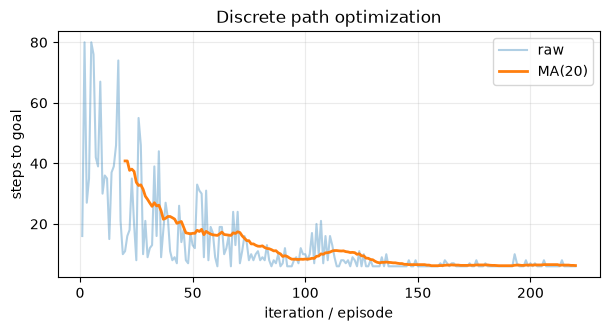

last-20 steps: 6.25 shortest possible: 6


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(21)
q = np.zeros((16, 4)); steps_history = []
moves = [(-1,0), (1,0), (0,-1), (0,1)]
for episode in range(220):
    state = 0
    for step in range(80):
        action = rng.integers(4) if rng.random() < max(.05, 1-episode/160) else np.argmax(q[state])
        row, col = divmod(state, 4); dr, dc = moves[action]
        nr, nc = np.clip(row+dr, 0, 3), np.clip(col+dc, 0, 3)
        ns = int(nr*4+nc); done = ns == 15; reward = 1.0 if done else -.02
        target = reward if done else reward + .95 * q[ns].max()
        q[state, action] += .2 * (target - q[state, action])
        state = ns
        if done: break
    steps_history.append(step + 1)

plot_curve(steps_history, "Discrete path optimization", "steps to goal", window=20)
print("last-20 steps:", np.mean(steps_history[-20:]), "shortest possible: 6")


### 曲线怎么读

步数移动平均应从截断上限降向最短路径 6。求解类任务还应报告 solved rate、search nodes 与最优性 gap，不能只报告训练 reward。

### 调参过程：一次只改变一个因素

- 先用可验证最短路的小实例检查状态编码和逆动作。
- 先调探索和 replay，使 solved rate 上升，再增加搜索宽度。
- 按 scramble depth 分层报告，不让简单样本掩盖困难样本。

### 失败案例复盘

- 数据生成只含浅层 scramble，深层测试完全失败。
- 状态哈希或对称化不一致，重复状态无法合并。
- MCTS/搜索找到解但路径包含互相抵消动作，未报告解长质量。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 对动作逆操作与状态编码写 round-trip 测试。
- 训练集要覆盖不同打乱深度，否则启发式在深层状态上失真。
- 报告解出率、解长度、展开节点数和时间，而不只是网络 loss。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

把 beam width 改为 1 和 10，比较是否找到路径及展开规模；解释贪心搜索的风险。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

width=1 是贪心 beam，内存小但容易剪掉正确路径；width=10 保留更多候选，解出率通常更高但展开量增加。记录是否找到、路径长度和候选数量，不能只比较运行时间。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- 离散优化可统一成状态图搜索。
- 网络常作为启发式，而搜索负责组合与验证。
- 学习启发式快但通常没有 admissibility 保证。
- 解出率、路径长度和展开节点数要一起报告。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**为什么学习到的 heuristic 可能破坏 A* 最优性？beam search 的 width 增大有什么变化？

<details>
<summary>展开答案</summary>

网络可能高估真实剩余代价，使最优路径被错误延后或剪枝。更大 width 保留更多候选、通常提高解出率，但时间和内存增长。
</details>


## 17. 与前后章节连接

第 22 章从单一求解器进入多个同时行动的 agent；状态、动作和经验的对齐问题会更复杂。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

curriculum learning 可逐渐增加打乱深度；bidirectional search、MCTS 与 transposition table 可进一步降低搜索量。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-21) · [← 学习索引](README.md)
